# From patches to a whole slide

The main project classifies pre-cut 224 × 224 patches. This notebook works with a **whole slide image (WSI)**
instead, using three standard computational-pathology tools:

1. **OpenSlide**: open the slide, inspect its resolution pyramid, read regions at different zoom levels.
2. **TIAToolbox**: tissue detection, patch extraction and whole-slide inference with a pretrained
   `resnet18-kather100k` model (trained on the same nine Kather classes as the main project).
3. **QuPath**: the tissue map is exported as GeoJSON so it can be opened on top of the slide.

It also revisits a finding from the main project, that per-patch Macenko normalisation silently damaged debris
and background, by comparing per-patch with **slide-level** stain normalisation.

Run it from the `wsi/` folder: `uv run jupyter lab`.

## 1. Settings

In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import openslide
import pandas as pd
import torch
import zarr
from PIL import Image
from scipy import ndimage

from tiatoolbox.models.engine.io_config import IOPatchPredictorConfig
from tiatoolbox.models.engine.patch_predictor import PatchPredictor
from tiatoolbox.tools import stainnorm
from tiatoolbox.utils.misc import download_data
from tiatoolbox.wsicore.wsireader import WSIReader

# --- data -----------------------------------------------------------------
# A colorectal adenocarcinoma slide from TCGA, the one TIAToolbox uses in its own tutorial (~1 GB).
WSI_URL = (
    "https://tiatoolbox.dcs.warwick.ac.uk/sample_wsis/"
    "TCGA-3L-AA1B-01Z-00-DX1.8923A151-A690-40B7-9E5A-FCBEDFC2394F.svs"
)
DATA_DIR = Path("data")
WSI_PATH = DATA_DIR / "sample_wsi.svs"
OUT_DIR = Path("outputs")
FIG_DIR = Path("../figs")                      # the repo's figure folder, used by the README

# Macenko target: the same training patch used as reference in the main project (falls back to TIAToolbox's own target)
KATHER_REFERENCE = Path("../data/NCT-CRC-HE-100K/TUM/TUM-AAALPREY.tif")

# --- processing -------------------------------------------------------------
OVERVIEW_MPP = 4.0          # resolution of overview images and masks (microns per pixel)
PATCH_MPP = 0.5             # Kather patches are 224 px at 0.5 µm/px (112 µm wide)
PATCH_SIZE = 224
RUN_FULL_SLIDE = False      # False = a tissue-rich region only (minutes); True = all tissue (much longer)
ROI_SIZE_UM = 4000          # side of the square region used when RUN_FULL_SLIDE is False
MODEL = "resnet18-kather100k"
BATCH_SIZE = 64
NUM_WORKERS = 0             # 0 is the safe choice inside Jupyter on macOS

if torch.backends.mps.is_available():
    DEVICE = "mps"          # Apple GPU; set to "cpu" if a model operation is not supported on MPS
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

# Kather 100K label order used by TIAToolbox's pretrained models (not alphabetical)
CLASSES = ["BACK", "NORM", "DEB", "TUM", "ADI", "MUC", "MUS", "STR", "LYM"]
NAMES = {
    "BACK": "Background", "NORM": "Normal mucosa", "DEB": "Debris", "TUM": "Tumour epithelium",
    "ADI": "Adipose", "MUC": "Mucus", "MUS": "Smooth muscle", "STR": "Stroma", "LYM": "Lymphocytes",
}
COLOURS = {  # one fixed colour per tissue type
    "BACK": "#d9d9d9", "NORM": "#4daf4a", "DEB": "#a65628", "TUM": "#e41a1c", "ADI": "#ffff33",
    "MUC": "#80b1d3", "MUS": "#984ea3", "STR": "#ff7f00", "LYM": "#377eb8",
}

for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)

Device: mps


## 2. Download the slide

In [2]:
if not WSI_PATH.exists():
    print("Downloading the sample slide (about 1 GB)...")
    download_data(WSI_URL, save_path=WSI_PATH)
print(f"{WSI_PATH}: {WSI_PATH.stat().st_size / 1e9:.2f} GB")

data/sample_wsi.svs: 1.23 GB


## 3. OpenSlide: the resolution pyramid

A WSI is far too large to load as one image. It is stored as a *pyramid*: the full-resolution image (level 0)
plus progressively downsampled copies, each split into tiles. Software reads only the region and level it needs.

In [3]:
slide = openslide.OpenSlide(str(WSI_PATH))
mpp = float(slide.properties.get(openslide.PROPERTY_NAME_MPP_X, "nan"))
power = slide.properties.get(openslide.PROPERTY_NAME_OBJECTIVE_POWER, "unknown")

w, h = slide.dimensions
print(f"Full size: {w:,} x {h:,} px  ({w * h / 1e9:.1f} gigapixels)")
print(f"Resolution: {mpp:.3f} µm/px at level 0, scanned at {power}x")
print(f"Physical size: {w * mpp / 1000:.1f} x {h * mpp / 1000:.1f} mm")
print(f"Uncompressed RGB at level 0 would need {w * h * 3 / 1e9:.1f} GB of memory")
print()
print(pd.DataFrame({
    "width": [d[0] for d in slide.level_dimensions],
    "height": [d[1] for d in slide.level_dimensions],
    "downsample": [round(x, 1) for x in slide.level_downsamples],
    "µm/px": [round(mpp * x, 2) for x in slide.level_downsamples],
}).rename_axis("level").to_string())

Full size: 95,615 x 74,462 px  (7.1 gigapixels)
Resolution: 0.253 µm/px at level 0, scanned at 40x
Physical size: 24.2 x 18.8 mm
Uncompressed RGB at level 0 would need 21.4 GB of memory

       width  height  downsample  µm/px
level                                  
0      95615   74462         1.0   0.25
1      23903   18615         4.0   1.01
2       5975    4653        16.0   4.04
3       2987    2326        32.0   8.09


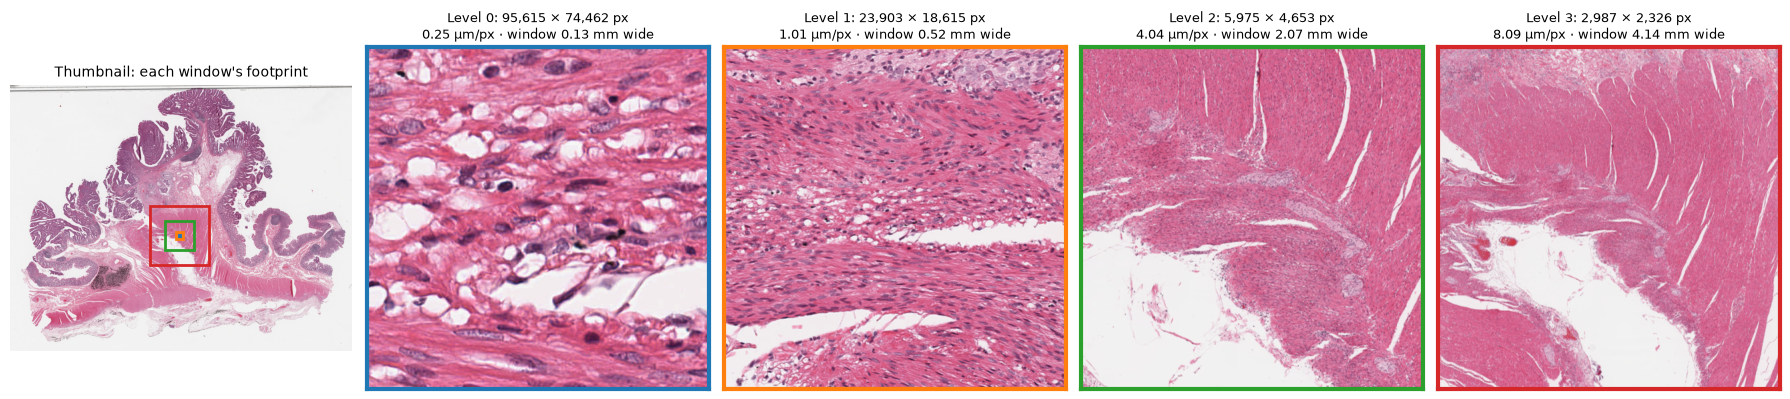

In [14]:
# All pyramid levels: the same 512 x 512 pixel window read at every level, centred on tissue.
# Coarser levels cover a larger area of the slide with less detail.
WINDOW = 512

thumb = slide.get_thumbnail((1024, 1024))
grey = np.asarray(thumb.convert("L"))
ys, xs = np.nonzero(grey < 220)                  # tissue is darker than the glass
s = slide.dimensions[0] / grey.shape[1]          # thumbnail pixel -> level-0 pixel
cx, cy = int(np.median(xs) * s), int(np.median(ys) * s)

n = slide.level_count
colours = plt.cm.tab10.colors
fig, axes = plt.subplots(1, n + 1, figsize=(3.6 * (n + 1), 4.4))

axes[0].imshow(thumb)
axes[0].set_title("Thumbnail: each window's footprint", fontsize=10)
for lvl in range(n):
    ds = slide.level_downsamples[lvl]
    lw, lh = slide.level_dimensions[lvl]
    win = (min(WINDOW, lw), min(WINDOW, lh))
    # read_region takes the top-left corner in level-0 pixels and the size in pixels of the chosen level
    x0 = int(np.clip(cx - win[0] * ds / 2, 0, slide.dimensions[0] - win[0] * ds))
    y0 = int(np.clip(cy - win[1] * ds / 2, 0, slide.dimensions[1] - win[1] * ds))
    region = slide.read_region((x0, y0), lvl, win).convert("RGB")

    ax = axes[lvl + 1]
    ax.imshow(region)
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_edgecolor(colours[lvl % 10])
        side.set_linewidth(3)
    width_mm = win[0] * ds * mpp / 1000
    ax.set_title(f"Level {lvl}: {lw:,} × {lh:,} px\n{mpp * ds:.2f} µm/px · window {width_mm:.2f} mm wide",
                 fontsize=9)
    axes[0].add_patch(mpatches.Rectangle((x0 / s, y0 / s), win[0] * ds / s, win[1] * ds / s, fill=False,
                                         edgecolor=colours[lvl % 10], linewidth=2))
axes[0].axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "wsi_pyramid_levels.png", dpi=150, bbox_inches="tight")
plt.show()

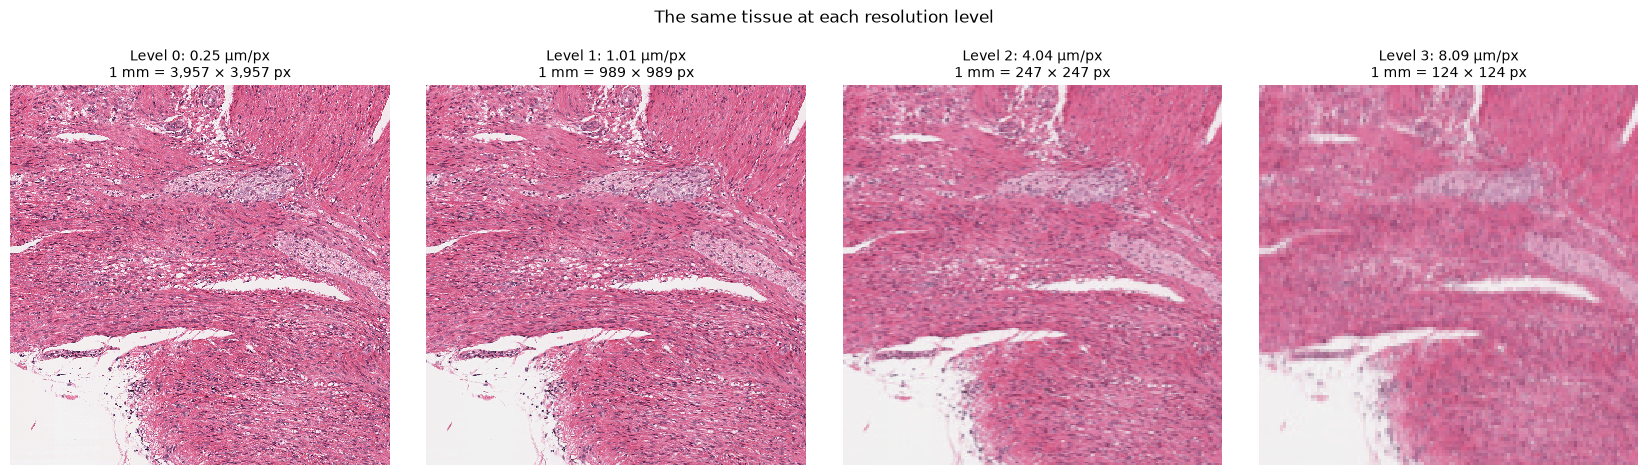

In [15]:
# The same area of tissue read at every pyramid level: less detail at each coarser level
REGION_UM = 1000                                 # side of the square shown (1 mm)

thumb = slide.get_thumbnail((1024, 1024))
grey = np.asarray(thumb.convert("L"))
ys, xs = np.nonzero(grey < 220)                  # tissue is darker than the glass
s = slide.dimensions[0] / grey.shape[1]          # thumbnail pixel -> level-0 pixel
side0 = int(REGION_UM / mpp)                     # region side in level-0 pixels
x0 = int(np.clip(np.median(xs) * s - side0 / 2, 0, slide.dimensions[0] - side0))
y0 = int(np.clip(np.median(ys) * s - side0 / 2, 0, slide.dimensions[1] - side0))

n = slide.level_count
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.8), squeeze=False)
for lvl in range(n):
    ds = slide.level_downsamples[lvl]
    size = max(1, int(round(side0 / ds)))        # the same area, in this level's pixels
    region = slide.read_region((x0, y0), lvl, (size, size)).convert("RGB")
    ax = axes[0, lvl]
    ax.imshow(region, interpolation="nearest")   # show real pixels, no smoothing
    ax.axis("off")
    ax.set_title(f"Level {lvl}: {mpp * ds:.2f} µm/px\n{REGION_UM / 1000:g} mm = {size:,} × {size:,} px", fontsize=10)
fig.suptitle("The same tissue at each resolution level", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.92))           # leave room for the overall title
fig.savefig(FIG_DIR / "wsi_resolution_levels.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. TIAToolbox: tissue detection

TIAToolbox wraps OpenSlide (and other formats) behind one reader, and lets you ask for any resolution in physical
units such as microns per pixel, independent of the scanner's pyramid levels.

{'vendor': 'aperio', 'mpp': (np.float64(0.2527), np.float64(0.2527)), 'objective_power': 40.0, 'level_count': 4}
Overview: 6040 x 4704 px at 4.0 µm/px
Tissue covers 34% of the slide


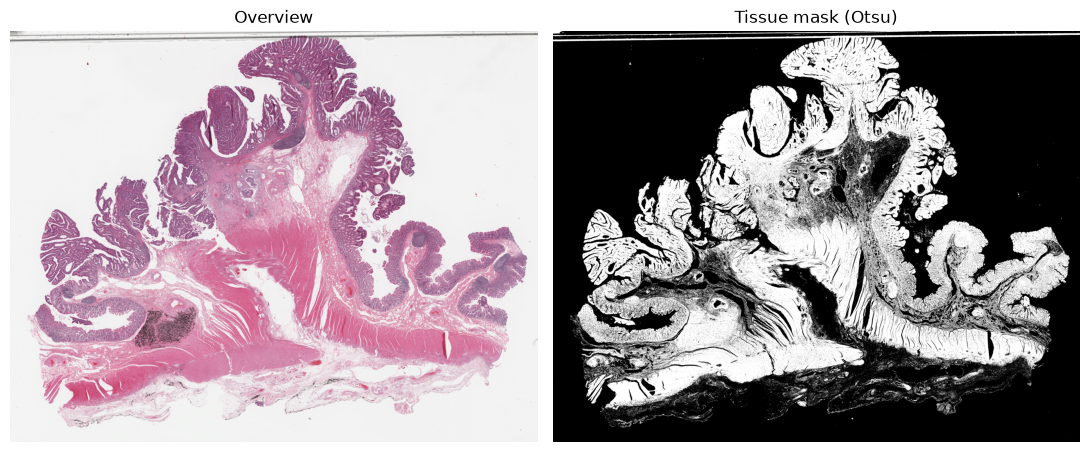

In [5]:
wsi = WSIReader.open(WSI_PATH)
info = wsi.info.as_dict()
print({k: info[k] for k in ("vendor", "mpp", "objective_power", "level_count")})

overview = wsi.slide_thumbnail(resolution=OVERVIEW_MPP, units="mpp")
mask_reader = wsi.tissue_mask(method="otsu", resolution=OVERVIEW_MPP, units="mpp")
tissue = mask_reader.slide_thumbnail(resolution=OVERVIEW_MPP, units="mpp")
tissue = (tissue[..., 0] if tissue.ndim == 3 else tissue) > 0
if tissue.shape != overview.shape[:2]:  # align sizes if they differ by a pixel
    tissue = np.array(Image.fromarray(tissue).resize(overview.shape[1::-1], Image.NEAREST))

base_mpp = float(np.mean(info["mpp"]))
to_base = OVERVIEW_MPP / base_mpp          # overview pixel -> level-0 pixel
print(f"Overview: {overview.shape[1]} x {overview.shape[0]} px at {OVERVIEW_MPP} µm/px")
print(f"Tissue covers {tissue.mean():.0%} of the slide")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(overview)
axes[0].set_title("Overview")
axes[1].imshow(tissue, cmap="gray")
axes[1].set_title("Tissue mask (Otsu)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Region of interest and patch extraction

Classifying every patch of a full slide takes a long time without a large GPU, so by default we use a square
region with the most tissue. Patches are 224 px at 0.5 µm/px, the same size and scale as the training data.

About 991 patches of 224 px at 0.5 µm/px to classify


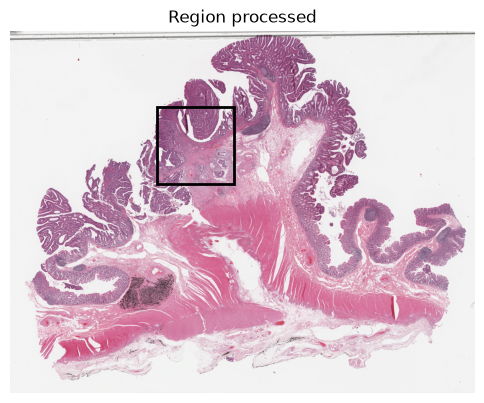

In [6]:
patch_ov = PATCH_SIZE * PATCH_MPP / OVERVIEW_MPP      # one patch in overview pixels

if RUN_FULL_SLIDE:
    region = tissue.copy()
    roi_box = None
else:
    side = int(round(ROI_SIZE_UM / OVERVIEW_MPP))
    side = min(side, *tissue.shape)
    density = ndimage.uniform_filter(tissue.astype(float), size=side, mode="constant")
    cy_ov, cx_ov = np.unravel_index(np.argmax(density), density.shape)
    y0 = int(np.clip(cy_ov - side // 2, 0, tissue.shape[0] - side))
    x0 = int(np.clip(cx_ov - side // 2, 0, tissue.shape[1] - side))
    roi_box = (x0, y0, side, side)
    region = np.zeros_like(tissue)
    region[y0:y0 + side, x0:x0 + side] = tissue[y0:y0 + side, x0:x0 + side]

mask_path = OUT_DIR / "processing_mask.png"
Image.fromarray(region.astype(np.uint8) * 255).save(mask_path)
n_patches = int(region.sum() / patch_ov**2)
print(f"About {n_patches:,} patches of {PATCH_SIZE} px at {PATCH_MPP} µm/px to classify")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(overview)
if roi_box:
    ax.add_patch(mpatches.Rectangle(roi_box[:2], roi_box[2], roi_box[3], fill=False,
                                    edgecolor="black", linewidth=2))
ax.set_title("Region processed" if roi_box else "Whole slide processed")
ax.axis("off")
plt.show()

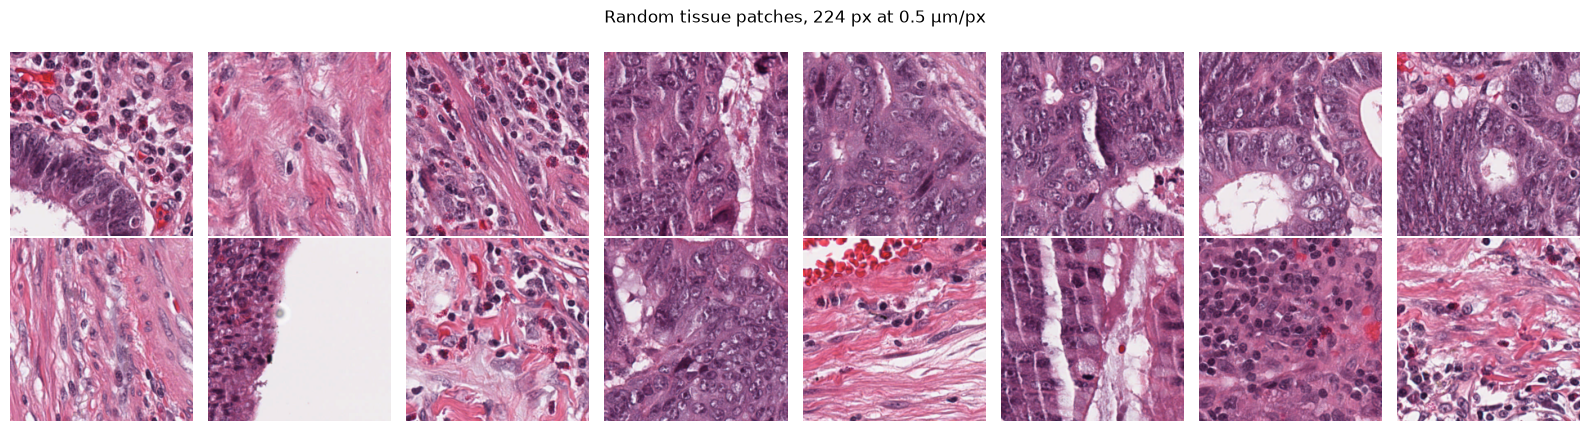

In [7]:
# A few patches exactly as the model will see them
rng = np.random.default_rng(0)
ys, xs = np.nonzero(region)
picks = rng.choice(len(xs), size=min(16, len(xs)), replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axes.ravel(), picks):
    loc = (int(xs[i] * to_base), int(ys[i] * to_base))
    ax.imshow(wsi.read_rect(location=loc, size=(PATCH_SIZE, PATCH_SIZE), resolution=PATCH_MPP, units="mpp"))
    ax.axis("off")
fig.suptitle(f"Random tissue patches, {PATCH_SIZE} px at {PATCH_MPP} µm/px")
plt.tight_layout()
plt.show()

## 6. Whole-slide inference

`PatchPredictor` tiles the processed region, classifies each patch and writes the predictions to a zarr store.
The pretrained weights are downloaded from Hugging Face on first use.

In [8]:
predictor = PatchPredictor(model=MODEL, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, device=DEVICE)
ioconfig = IOPatchPredictorConfig(
    input_resolutions=[{"units": "mpp", "resolution": PATCH_MPP}],
    patch_input_shape=[PATCH_SIZE, PATCH_SIZE],
    stride_shape=[PATCH_SIZE, PATCH_SIZE],
)

start = time.time()
output = predictor.run(
    images=[WSI_PATH],
    masks=[mask_path],
    patch_mode=False,
    ioconfig=ioconfig,
    save_dir=OUT_DIR / "predictions",
    overwrite=True,
    return_probabilities=True,
    device=DEVICE,
    num_workers=NUM_WORKERS,
    batch_size=BATCH_SIZE,
)
elapsed = time.time() - start

store = zarr.open(str(output[WSI_PATH]), mode="r")
preds = np.asarray(store["predictions"]).astype(int).ravel()
coords = np.asarray(store["coordinates"])            # x1, y1, x2, y2 at PATCH_MPP resolution
probs = np.asarray(store["probabilities"])
print(f"Classified {len(preds):,} patches in {elapsed:.0f} s ({len(preds) / max(elapsed, 1e-9):.0f} patches/s)")

|2026-11-19|12:47:57.107| [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
|2026-11-19|12:47:57.215| [INFO] HTTP Request: HEAD https://huggingface.co/TIACentre/TIAToolbox_pretrained_weights/resolve/main/resnet18-kather100k.pth "HTTP/1.1 302 Found"


|2026-11-19|12:47:57.218| [WARNING] Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


resnet18-kather100k.pth:   0%|          | 0.00/44.8M [00:00<?, ?B/s]

|2026-11-19|12:48:03.867| [WARNING] No GPU detected or cuda not installed, torch.compile is only supported on selected NVIDIA GPUs. Speedup numbers may be lower than expected.


|2026-11-19|12:48:03.868| [INFO] output_type has been updated to 'zarr' for saving the file to outputs/predictions.Remove `save_dir` input to return the output as a `dict`.
|2026-11-19|12:48:03.868| [INFO] When providing multiple whole slide images, the outputs will be saved and the locations of outputs will be returned to the calling function when `run()` finishes successfully.


Processing WSIs:   0%|          | 0/1 [00:00<?, ?it/s]

|2026-11-19|12:48:03.979| [WARNING] The image mode is set to 'feature' as the input dimensions do not match with binary mask or RGB/RGBA.


Inferring patches:   0%|          | 0/21 [00:00<?, ?it/s]

Saving output to outputs/predictions/sample_wsi.zarr.:   0%|          | 0/111 [00:00<?, ?it/s]

|2026-11-19|12:48:11.984| [INFO] Output file saved at outputs/predictions/sample_wsi.zarr.
Classified 1,310 patches in 8 s (159 patches/s)


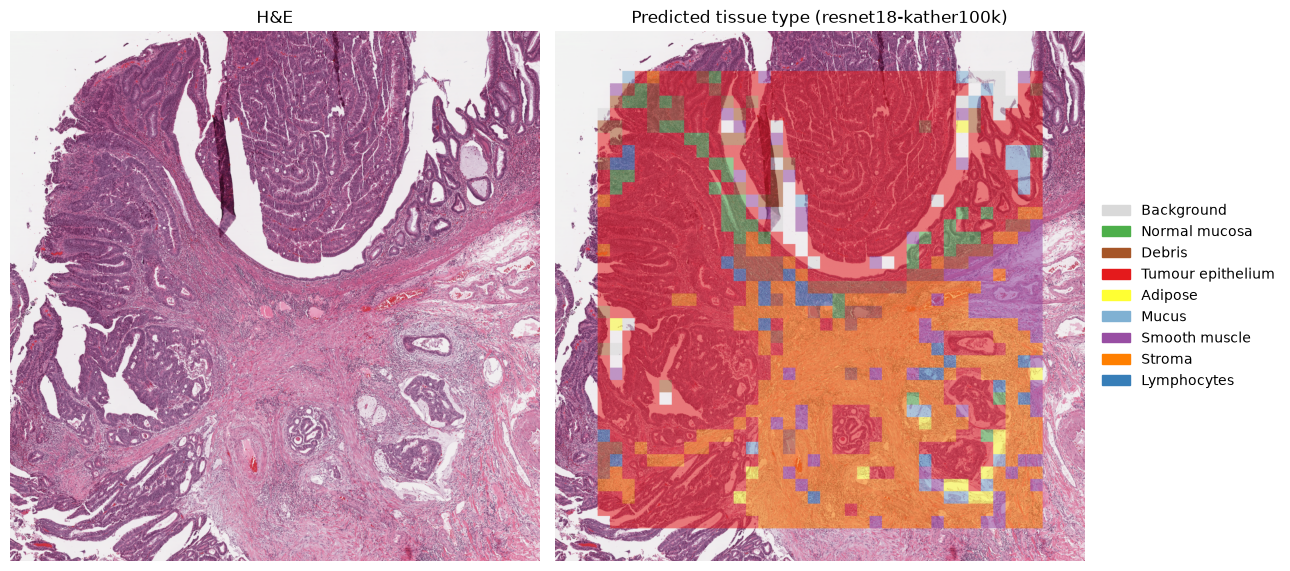

In [9]:
# Tissue-type map: each patch painted onto the overview in its predicted class colour
scale = OVERVIEW_MPP / PATCH_MPP
label_map = np.full(overview.shape[:2], -1, dtype=int)
for p, (x1, y1, x2, y2) in zip(preds, coords):
    label_map[int(y1 / scale):int(np.ceil(y2 / scale)), int(x1 / scale):int(np.ceil(x2 / scale))] = p

rgba = np.zeros((*label_map.shape, 4))
for k, c in enumerate(CLASSES):
    rgba[label_map == k] = (*plt.matplotlib.colors.to_rgb(COLOURS[c]), 0.55)

if roi_box:
    x0, y0, side, _ = roi_box
    pad = side // 10
    crop = (slice(max(0, y0 - pad), y0 + side + pad), slice(max(0, x0 - pad), x0 + side + pad))
else:
    crop = (slice(None), slice(None))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(overview[crop])
axes[0].set_title("H&E")
axes[1].imshow(overview[crop])
axes[1].imshow(rgba[crop])
model_name = MODEL if isinstance(MODEL, str) else type(MODEL).__name__
axes[1].set_title(f"Predicted tissue type ({model_name})")
for ax in axes:
    ax.axis("off")
present = [c for k, c in enumerate(CLASSES) if (preds == k).any()]
axes[1].legend(handles=[mpatches.Patch(color=COLOURS[c], label=NAMES[c]) for c in present],
               loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "wsi_tissue_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Composition of the processed tissue
counts = pd.Series(preds).map(dict(enumerate(CLASSES))).value_counts()
composition = pd.DataFrame({
    "tissue type": [NAMES[c] for c in counts.index],
    "patches": counts.values,
    "share of patches": (counts.values / counts.sum()).round(3),
    "area (mm²)": (counts.values * (PATCH_SIZE * PATCH_MPP / 1000) ** 2).round(2),
})
print(composition.to_string(index=False))
print(f"\nMean confidence of the top class: {probs.max(1).mean():.2f}")

      tissue type  patches  share of patches  area (mm²)
Tumour epithelium      703             0.537        8.82
           Stroma      330             0.252        4.14
    Smooth muscle       87             0.066        1.09
           Debris       74             0.056        0.93
    Normal mucosa       42             0.032        0.53
      Lymphocytes       24             0.018        0.30
            Mucus       19             0.015        0.24
       Background       17             0.013        0.21
          Adipose       14             0.011        0.18

Mean confidence of the top class: 0.92


## 7. Per-patch vs slide-level stain normalisation

In the main project, Macenko normalisation was applied **per patch**: each patch's own stain colours were
estimated from that patch alone. On debris and background there is too little typical stain to estimate them,
and accuracy dropped without any visible error.

Here the stain colours are instead estimated **once from many tissue patches across the slide**, and that one
estimate is applied to every patch. This is the usual approach for whole slides.

In [11]:
class SlideLevelMacenko(stainnorm.MacenkoNormalizer):
    """Macenko normalisation with the source stain colours estimated once for the whole slide."""

    def fit_source(self, sample: np.ndarray) -> None:
        self.stain_matrix_source = self.extractor.get_stain_matrix(sample.copy())
        conc = self.get_concentrations(sample.copy(), self.stain_matrix_source)
        self.max_c_source = np.percentile(conc, 99, axis=0).reshape((1, 2))

    def transform(self, img: np.ndarray) -> np.ndarray:
        conc = self.get_concentrations(img.copy(), self.stain_matrix_source)  # TIAToolbox edits its input
        conc *= self.maxC_target / self.max_c_source
        out = 255 * np.exp(-np.dot(conc, self.stain_matrix_target))
        return np.clip(out, 0, 255).reshape(img.shape).astype(np.uint8)


def read_patch(i):
    x1, y1 = coords[i][:2]
    loc = (int(x1 * PATCH_MPP / base_mpp), int(y1 * PATCH_MPP / base_mpp))   # PATCH_MPP coords -> level 0
    return wsi.read_rect(location=loc, size=(PATCH_SIZE, PATCH_SIZE), resolution=PATCH_MPP, units="mpp")


if KATHER_REFERENCE.exists():
    target = np.array(Image.open(KATHER_REFERENCE).convert("RGB"))   # a writable copy
    print("Target: Kather training patch", KATHER_REFERENCE.name)
else:
    from tiatoolbox import data
    target = np.array(data.stain_norm_target())
    print("Target: TIAToolbox's default stain target")

# Slide-level estimate from a mosaic of up to 64 patches predicted as tissue-rich classes
rng = np.random.default_rng(0)
tissue_rich = np.flatnonzero(np.isin(preds, [CLASSES.index(c) for c in ("TUM", "STR", "NORM", "LYM", "MUS")]))
if len(tissue_rich) < 8:                          # fall back to any non-background patch
    tissue_rich = np.flatnonzero(preds != CLASSES.index("BACK"))
if len(tissue_rich) == 0:
    tissue_rich = np.arange(len(preds))
sample_idx = rng.choice(tissue_rich, size=min(64, len(tissue_rich)), replace=False)
mosaic = np.concatenate([read_patch(i) for i in sample_idx], axis=1)

per_patch = stainnorm.MacenkoNormalizer()
per_patch.fit(target.copy())
slide_level = SlideLevelMacenko()
slide_level.fit(target.copy())
slide_level.fit_source(mosaic)
print(f"Slide-level stain estimate from {len(sample_idx)} patches")

Target: Kather training patch TUM-AAALPREY.tif
Slide-level stain estimate from 64 patches


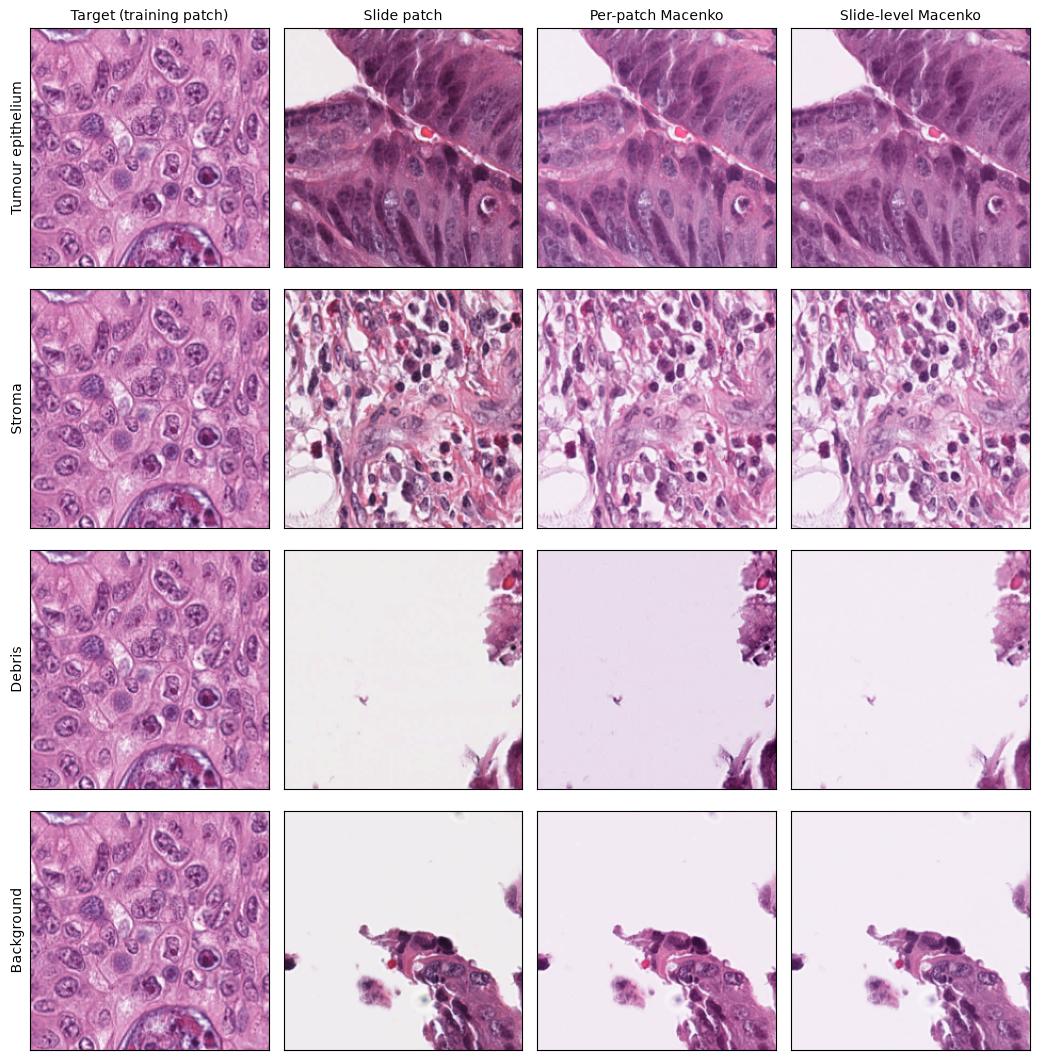

In [12]:
# Compare on one patch of each type: debris and background are where per-patch estimation struggled
show = [c for c in ("TUM", "STR", "DEB", "BACK") if (preds == CLASSES.index(c)).any()]
if not show:                                      # otherwise use the most common predicted types
    show = [CLASSES[k] for k in pd.Series(preds).value_counts().index[:4]]
fig, axes = plt.subplots(len(show), 4, figsize=(10.5, 2.7 * len(show)), squeeze=False)
titles = ["Target (training patch)", "Slide patch", "Per-patch Macenko", "Slide-level Macenko"]
for row, c in enumerate(show):
    i = rng.choice(np.flatnonzero(preds == CLASSES.index(c)))
    patch = read_patch(i)
    try:
        pp = per_patch.transform(patch.copy())
        pp_note = ""
    except Exception:
        pp, pp_note = patch, "failed: original shown"
    images = [target, patch, pp, slide_level.transform(patch.copy())]
    for col, img in enumerate(images):
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(titles[col], fontsize=10)
    axes[row, 0].set_ylabel(NAMES[c], fontsize=10)
    if pp_note:
        axes[row, 2].set_xlabel(pp_note, fontsize=8, color="crimson")
plt.tight_layout()
fig.savefig(FIG_DIR / "wsi_stain_slide_vs_patch.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Open the tissue map in QuPath

The predictions are written as GeoJSON in level-0 pixel coordinates, one square per patch with its class name and
colour. In QuPath: open `data/sample_wsi.svs`, then drag `outputs/sample_wsi_tissue_map.geojson` onto the viewer
(or use *File → Import objects from file*). Each patch appears as a detection that can be toggled, filtered by class
or measured.

In [13]:
to_level0 = PATCH_MPP / base_mpp
features = []
for p, (x1, y1, x2, y2) in zip(preds, coords):
    c = CLASSES[p]
    if c == "BACK":
        continue
    x1, y1, x2, y2 = (float(v) * to_level0 for v in (x1, y1, x2, y2))
    features.append({
        "type": "Feature",
        "geometry": {"type": "Polygon", "coordinates": [[[x1, y1], [x2, y1], [x2, y2], [x1, y2], [x1, y1]]]},
        "properties": {
            "objectType": "detection",
            "classification": {
                "name": NAMES[c],
                "color": [int(255 * v) for v in plt.matplotlib.colors.to_rgb(COLOURS[c])],
            },
        },
    })

geojson_path = OUT_DIR / "sample_wsi_tissue_map.geojson"
geojson_path.write_text(json.dumps({"type": "FeatureCollection", "features": features}))
print(f"Wrote {len(features):,} patch detections to {geojson_path}")

Wrote 1,293 patch detections to outputs/sample_wsi_tissue_map.geojson


## Summary

- The slide is a multi-gigapixel pyramid; OpenSlide reads only the region and level needed.
- TIAToolbox detected tissue, extracted patches at the training scale (224 px at 0.5 µm/px) and classified them
  with a model trained on the same nine tissue types as the main project, producing a tissue-type map.
- Slide-level stain estimation applies one consistent colour mapping to every patch, avoiding the unreliable
  per-patch estimates on debris and background seen in the main project.
- The map opens in QuPath on top of the slide for inspection.